# Полный цикл распознавания символов с k-NN
Этот ноутбук содержит полностью рабочий самодостаточный пример. Чтобы не зависеть от внешних файлов, мы сгенерируем **синтетический набор данных** прямо в памяти, обучим на нем классификатор, а затем визуализируем процесс распознавания тестовой строки.

In [1]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

IMAGE_SIZE = 32
class_names = ['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'h', 't', '*', 'w', 'y']

## 1. Генерация синтетических данных для обучения
Имитируем датасет, отрисовывая символы с помощью OpenCV (`cv2.putText`). Мы добавим случайный шум, смещения и масштабирование, чтобы сделать данные более реалистичными.

In [2]:
print("Генерация датасета...")
X_data = []
y_data = []

for i, char in enumerate(class_names):
    # Создаем по 100 образцов каждого символа
    for _ in range(100):
        img = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
        
        # Случайное смещение и масштаб для разнообразия
        offset_x = random.randint(-4, 4)
        offset_y = random.randint(-4, 4)
        font_scale = random.uniform(0.7, 1.0)
        
        cv2.putText(img, char, (8 + offset_x, 24 + offset_y), 
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, 255, 2)
        
        # Добавляем шум
        noise = np.random.randint(0, 50, (IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
        img = cv2.add(img, noise)
        
        # Векторизация и нормализация
        X_data.append(img.flatten().astype(float) / 255.0)
        y_data.append(i)

X_data = np.array(X_data)
y_data = np.array(y_data)
print(f"Сгенерировано объектов: {X_data.shape[0]}, признаков: {X_data.shape[1]}")

Генерация датасета...
Сгенерировано объектов: 2000, признаков: 1024


## 2. Обучение классификатора k-NN
Перебираем гиперпараметр $k$ для поиска оптимальной модели на тестовой выборке.

In [3]:
def train_optimal_knn(X, y, max_k=10):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    best_k = 1
    best_acc = 0.0
    best_model = None
    
    for k in range(1, max_k + 1):
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train, y_train)
        preds = knn.predict(X_test)
        acc = accuracy_score(y_test, preds)
        
        if acc > best_acc:
            best_acc = acc
            best_k = k
            best_model = knn
            
    print(f"Оптимальный параметр k={best_k}, Accuracy на тесте: {best_acc:.4f}")
    return best_model

knn_model = train_optimal_knn(X_data, y_data)

Оптимальный параметр k=1, Accuracy на тесте: 0.9700


## 3. Выделение объектов и пайплайн распознавания
Используем бинаризацию и контуры OpenCV для сегментации символов на входном изображении, а затем классифицируем каждый вырезанный сегмент.

In [4]:
def extract_objects(img_gray):
    ret, thresh = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    crops = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 30: # Пропускаем слишком мелкие артефакты
            crops.append((x, y, w, h))
            
    return sorted(crops, key=lambda item: item[0]), thresh

def recognize_pipeline(text_image, knn_model, class_names):
    crops, thresh = extract_objects(text_image)
    predicted_sequence = []
    
    for (x, y, w, h) in crops:
        char_img = thresh[y:y+h, x:x+w]
        
        # Центрируем вырезанный символ с небольшими отступами
        base = np.zeros((char_img.shape[0] + 8, char_img.shape[1] + 8), dtype=np.uint8)
        base[4:char_img.shape[0]+4, 4:char_img.shape[1]+4] = char_img
        
        resized = cv2.resize(base, (IMAGE_SIZE, IMAGE_SIZE))
        feature_vector = resized.flatten().reshape(1, -1).astype(float) / 255.0
        
        pred_idx = knn_model.predict(feature_vector)[0]
        predicted_sequence.append(class_names[pred_idx])
        
    return "".join(predicted_sequence), crops

## 4. Тестирование и визуализация
Сгенерируем зашумленную тестовую картинку со строкой **"t*7"**, прогоним через пайплайн и визуализируем результат с bounding boxes (ограничивающими рамками).


>>> ИТОГОВЫЙ РЕЗУЛЬТАТ РАСПОЗНАВАНИЯ: tw7 <<<



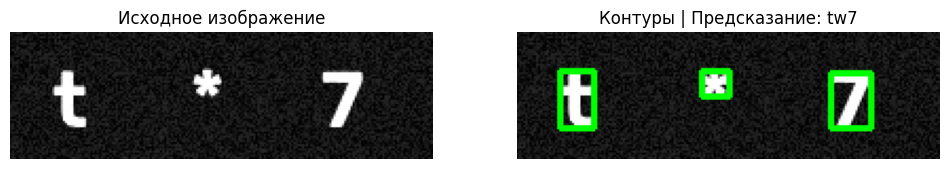

In [ ]:
# Создаем тестовое изображение
test_img = np.zeros((60, 200), dtype=np.uint8)
cv2.putText(test_img, "t", (20, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.3, 255, 3)
cv2.putText(test_img, "*", (85, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.3, 255, 3)
cv2.putText(test_img, "7", (145, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.3, 255, 3)

# Добавляем фоновый шум
noise = np.random.randint(0, 40, test_img.shape, dtype=np.uint8)
test_img = cv2.add(test_img, noise)

test_img = 

# Запуск распознавания
result, bboxes = recognize_pipeline(test_img, knn_model, class_names)
print(f"\n>>> ИТОГОВЫЙ РЕЗУЛЬТАТ РАСПОЗНАВАНИЯ: {result} <<<\n")

# Отрисовка зеленых рамок вокруг найденных контуров
vis_img = cv2.cvtColor(test_img, cv2.COLOR_GRAY2BGR)
for (x, y, w, h) in bboxes:
    cv2.rectangle(vis_img, (x, y), (x+w, y+h), (0, 255, 0), 2)

# Вывод графиков
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(test_img, cmap='gray')
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(vis_img)
axes[1].set_title(f'Контуры | Предсказание: {result}')
axes[1].axis('off')
plt.show()